# Melatih dan Membandingkan SVM vs Random Forest
### Prediksi Penyakit Liver

Notebook ini melatih **dua algoritma** pada data pasien liver, mengujinya dengan cara yang sama, lalu menyimpan hasilnya untuk dipakai aplikasi web (`webSVM.py`).

**Cara memakai:** letakkan notebook ini di **dalam folder `notebook/`** pada folder proyek (atau langsung di folder proyek). Notebook mencari `Data_Pasien_penyakit_liver.csv` otomatis. Lalu jalankan sel dari atas ke bawah (**Run All**). Butuh sekitar 1 sampai 3 menit.

**Hasil yang dibuat (disimpan di folder proyek, tempat CSV berada):** `svm_liver_pickle`, `rf_liver_pickle`, dan `metrik_perbandingan.json`.

**Catatan:** notebook ini adalah versi belajar dari `train_models.py`. File `train_models.py` tetap dibutuhkan oleh aplikasi web, jadi jangan dihapus.

**Pustaka yang dibutuhkan:** `pip install pandas numpy scikit-learn matplotlib seaborn`

| No | Langkah | No | Langkah |
|---|---|---|---|
| 1 | Import library | 9 | Model 2: Random Forest |
| 2 | Panggil dataset | 10 | Menguji model (menghitung nilai) |
| 3 | Kenali dan rapikan data | 11 | Confusion matrix |
| 4 | Cek kualitas data | 12 | Fitur terpenting |
| 5 | Lihat distribusi target | 13 | Uji selisih (bootstrap) |
| 6 | Pisahkan fitur dan target | 14 | Simpan hasil |
| 7 | Bagi data latih dan uji | 15 | Coba prediksi satu pasien |
| 8 | Model 1: SVM | 16 | Kesimpulan |

## 1. Import Library

**Apa ini?** Memanggil "alat bantu" siap pakai supaya tidak perlu menulis semuanya dari nol.

| Library | Fungsinya |
|---|---|
| `pandas` | mengolah data berbentuk tabel (seperti Excel) |
| `numpy` | perhitungan angka |
| `matplotlib`, `seaborn` | membuat grafik |
| `scikit-learn` (`sklearn`) | algoritma machine learning dan penilaiannya |
| `pickle`, `json` | menyimpan model dan angka hasil ke file |

In [1]:
import os
import json
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")          # sembunyikan peringatan agar tampilan bersih
sns.set_theme(style="whitegrid")           # gaya grafik
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")   # angka ditampilkan 3 desimal

print("Library berhasil di-import")

Library berhasil di-import


## 2. Panggil Dataset

**Apa ini?** Membaca file CSV menjadi tabel bernama `df` (DataFrame).

- `df.shape` = (jumlah baris, jumlah kolom)
- `df.head()` = menampilkan 5 baris pertama untuk melihat isi data

Notebook mencari CSV di folder notebook ini, lalu di satu folder di atasnya (folder proyek). Variabel `FOLDER` mencatat lokasi yang ditemukan, dan nanti dipakai untuk menyimpan hasil. Di Google Colab akan muncul tombol upload.

In [2]:
NAMA_FILE = "Data_Pasien_penyakit_liver.csv"

# Cari CSV: di folder notebook ini, atau satu folder di atasnya (folder proyek)
FOLDER = next((f for f in [".", ".."] if os.path.exists(os.path.join(f, NAMA_FILE))), None)

if FOLDER is None:
    try:                                           # jika dijalankan di Google Colab
        from google.colab import files
        print("Silakan upload file CSV Anda:")
        NAMA_FILE = list(files.upload().keys())[0]
        FOLDER = "."
    except ImportError:
        raise FileNotFoundError(f"File '{NAMA_FILE}' tidak ditemukan. Taruh di folder proyek (satu tingkat di atas folder notebook).")

df = pd.read_csv(os.path.join(FOLDER, NAMA_FILE))
print(f"Data dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat: 579 baris, 11 kolom


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,0,0.700,0.100,187,16,18,6.800,3.300,0.900,1
1,62,1,10.900,5.500,699,64,100,7.500,3.200,0.740,1
2,62,1,7.300,4.100,490,60,68,7.000,3.300,0.890,1
3,58,1,1.000,0.400,182,14,20,6.800,3.400,1.000,1
4,72,1,3.900,2.000,195,27,59,7.300,2.400,0.400,1


## 3. Kenali dan Rapikan Data

**Apa ini?** Dua nama kolom pada file asli salah ketik, jadi diperbaiki:
`Alamine_Aminotransferase` menjadi `Alanine_Aminotransferase`, dan `Total_Protiens` menjadi `Total_Proteins`.

`df.info()` menunjukkan tipe data tiap kolom dan jumlah isinya.

**Arti kolom target `Dataset`:** `1` = pasien liver, `2` = bukan pasien liver.

In [3]:
df = df.rename(columns={
    "Alamine_Aminotransferase": "Alanine_Aminotransferase",
    "Total_Protiens": "Total_Proteins",
})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 579 entries, 0 to 578
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         579 non-null    int64  
 1   Gender                      579 non-null    int64  
 2   Total_Bilirubin             579 non-null    float64
 3   Direct_Bilirubin            579 non-null    float64
 4   Alkaline_Phosphotase        579 non-null    int64  
 5   Alanine_Aminotransferase    579 non-null    int64  
 6   Aspartate_Aminotransferase  579 non-null    int64  
 7   Total_Proteins              579 non-null    float64
 8   Albumin                     579 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     579 non-null    int64  
dtypes: float64(5), int64(6)
memory usage: 49.9 KB


## 4. Cek Kualitas Data (Kosong dan Kembar)

**Kenapa penting?**
- **Data kosong (missing value)** bisa membuat model error.
- **Baris kembar (duplikat)** berbahaya: baris yang sama bisa jatuh ke data latih **dan** data uji, sehingga model seolah-olah "menyontek" dan nilainya terlihat lebih bagus dari sebenarnya.

Karena itu baris kembar dihapus.

In [4]:
print("Jumlah data kosong per kolom:")
print(df.isna().sum().to_string())

n_dup = df.duplicated().sum()
print(f"\nBaris kembar: {n_dup}")

sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Baris sebelum: {sebelum}  ->  sesudah: {len(df)}")

Jumlah data kosong per kolom:
Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alanine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Dataset                       0

Baris kembar: 13
Baris sebelum: 579  ->  sesudah: 566


## 5. Lihat Distribusi Target

**Apa ini?** Menghitung berapa pasien liver dan berapa yang bukan.

**Kenapa penting?** Jika satu kelas jauh lebih banyak (tidak seimbang), model bisa menebak "semua pasien liver" dan akurasinya tetap terlihat tinggi. Itu sebabnya nanti dipakai **akurasi seimbang** dan pengaturan **`class_weight="balanced"`**.

,Jumlah,Persentase (%)
Dataset,,
Pasien Liver,404,71.378
Bukan Pasien Liver,162,28.622


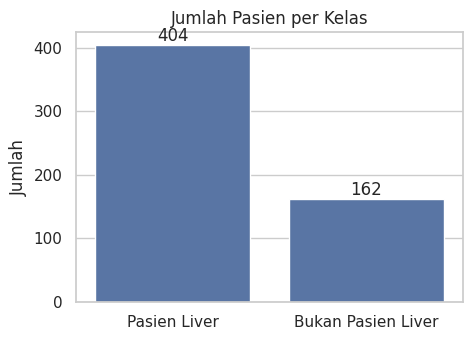

In [5]:
tabel = df["Dataset"].map({1: "Pasien Liver", 2: "Bukan Pasien Liver"}).value_counts().to_frame("Jumlah")
tabel["Persentase (%)"] = tabel["Jumlah"] / len(df) * 100
display(tabel)

plt.figure(figsize=(5, 3.5))
ax = sns.barplot(x=tabel.index, y=tabel["Jumlah"])
ax.set_title("Jumlah Pasien per Kelas"); ax.set_xlabel(""); ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

## 6. Pisahkan Fitur (X) dan Target (y)

**Apa ini?**
- **`X` (fitur)** = bahan yang dipakai model untuk menebak (10 kolom hasil lab dan identitas pasien).
- **`y` (target)** = jawaban yang benar (1 atau 2).

**Penting:** urutan `FITUR` harus **sama** dengan yang dipakai aplikasi web. Jangan diubah urutannya.

In [6]:
FITUR = ["Age", "Gender", "Total_Bilirubin", "Direct_Bilirubin", "Alkaline_Phosphotase",
         "Alanine_Aminotransferase", "Aspartate_Aminotransferase", "Total_Proteins",
         "Albumin", "Albumin_and_Globulin_Ratio"]

X = df[FITUR]
y = df["Dataset"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
X.head()

Bentuk X: (566, 10) | Bentuk y: (566,)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alanine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio
0,65,0,0.700,0.100,187,16,18,6.800,3.300,0.900
1,62,1,10.900,5.500,699,64,100,7.500,3.200,0.740
2,62,1,7.300,4.100,490,60,68,7.000,3.300,0.890
3,58,1,1.000,0.400,182,14,20,6.800,3.400,1.000
4,72,1,3.900,2.000,195,27,59,7.300,2.400,0.400


## 7. Bagi Data: Latih (70%) dan Uji (30%)

**Analogi:** data latih = soal latihan untuk belajar, data uji = soal ujian yang **belum pernah dilihat**. Model dinilai dari ujiannya, bukan dari latihannya.

| Pengaturan | Artinya |
|---|---|
| `test_size=0.3` | 30% data disisihkan untuk ujian |
| `stratify=y` | perbandingan pasien liver dan bukan dijaga sama di kedua bagian |
| `random_state=0` | pembagian selalu sama setiap dijalankan (hasil bisa diulang) |

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(f"Data latih: {len(X_train)} pasien | Data uji: {len(X_test)} pasien")
print("Proporsi pasien liver di data latih:", f"{(y_train == 1).mean():.1%}",
      "| di data uji:", f"{(y_test == 1).mean():.1%}")

Data latih: 396 pasien | Data uji: 170 pasien
Proporsi pasien liver di data latih: 71.5% | di data uji: 71.2%


## 8. Model 1: SVM (Support Vector Machine)

**Apa ini?** SVM mencari batas pemisah terbaik antara dua kelas. Dipakai kernel **RBF** agar batasnya bisa melengkung.

**Isi `Pipeline` (dua langkah berurutan):**
1. `StandardScaler` menyamakan skala angka (AST bisa ribuan, albumin hanya sekitar 3). SVM sensitif terhadap skala.
2. `SVC` adalah SVM itu sendiri, dengan `class_weight="balanced"`.

**`GridSearchCV`** mencoba semua kombinasi pengaturan, menilai tiap kombinasi lewat validasi silang 5 bagian (`cv`), lalu memilih yang terbaik berdasarkan **akurasi seimbang**.

| Pengaturan | Artinya |
|---|---|
| `C` | toleransi terhadap kesalahan (kecil = longgar, besar = ketat) |
| `gamma` | seberapa jauh pengaruh satu data (kecil = luas, besar = sempit) |

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)      # aturan validasi silang (dipakai kedua model)

grid_svm = GridSearchCV(
    Pipeline([("scaler", StandardScaler()),
              ("svm", SVC(kernel="rbf", class_weight="balanced"))]),
    {"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.1]},     # 4 x 3 = 12 kombinasi
    scoring="balanced_accuracy", cv=cv)

t = time.time()
grid_svm.fit(X_train, y_train)                             # proses belajar
waktu_svm = time.time() - t

print("Pengaturan terbaik SVM:", grid_svm.best_params_)
print(f"Akurasi seimbang validasi silang: {grid_svm.best_score_:.3f}")
print(f"Lama pelatihan: {waktu_svm:.1f} detik")

Pengaturan terbaik SVM: {'svm__C': 10, 'svm__gamma': 0.01}
Akurasi seimbang validasi silang: 0.682
Lama pelatihan: 0.6 detik


## 9. Model 2: Random Forest

**Apa ini?** Kumpulan banyak **pohon keputusan**. Tiap pohon belajar dari sampel acak data, lalu semua pohon **memberi suara** dan hasil terbanyak dipilih.

**Bedanya dengan SVM:** tidak perlu menyamakan skala, dan relatif tahan terhadap nilai ekstrem. Cocok untuk data ini yang banyak nilai ekstrem.

| Pengaturan | Artinya |
|---|---|
| `n_estimators` | jumlah pohon |
| `max_depth` | kedalaman maksimum pohon (`None` = tanpa batas) |
| `min_samples_leaf` | minimal jumlah data di ujung pohon (besar = lebih sederhana) |
| `max_features` | jumlah fitur yang dilihat tiap percabangan |

Dicoba 2 x 3 x 3 x 2 = **36 kombinasi** (bagian ini paling lama).

In [9]:
grid_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=0, n_jobs=-1),
    {"n_estimators": [200, 500], "max_depth": [None, 6, 12],
     "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5]},
    scoring="balanced_accuracy", cv=cv)

t = time.time()
grid_rf.fit(X_train, y_train)
waktu_rf = time.time() - t

print("Pengaturan terbaik Random Forest:", grid_rf.best_params_)
print(f"Akurasi seimbang validasi silang: {grid_rf.best_score_:.3f}")
print(f"Lama pelatihan: {waktu_rf:.1f} detik")

Pengaturan terbaik Random Forest: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 500}
Akurasi seimbang validasi silang: 0.655
Lama pelatihan: 83.1 detik


## 10. Menguji Model pada Data Uji (Menghitung Nilai)

**Apa ini?** Kedua model menebak data uji, lalu tebakannya dibandingkan dengan jawaban asli.

| Ukuran | Artinya |
|---|---|
| **Akurasi** | persentase tebakan yang benar (bisa menipu jika data tidak seimbang) |
| **Akurasi seimbang** | rata-rata kemampuan mengenali kedua kelas. **Ukuran utama** di sini |
| **Recall** | dari semua pasien yang *benar-benar* kelas itu, berapa yang berhasil dikenali |
| **Precision** | dari semua yang *ditebak* kelas itu, berapa yang benar |
| **F1** | gabungan precision dan recall |
| **ROC-AUC** | kemampuan membedakan kedua kelas (0,5 = asal tebak, 1 = sempurna) |

Fungsi `hitung_metrik` mengumpulkan semua nilai ini dalam satu kamus (dictionary).

In [10]:
def skor_kelas_liver(model, X):
    """Skor 'kemungkinan pasien liver' (dipakai untuk ROC-AUC)."""
    if hasattr(model, "predict_proba"):                       # Random Forest punya peluang
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    return -model.decision_function(X)                        # SVM: nilai positif = kelas 2, jadi dibalik


def hitung_metrik(model, grid, waktu):
    y_pred = model.predict(X_test)
    lap = classification_report(y_test, y_pred, output_dict=True)
    return {
        "akurasi": accuracy_score(y_test, y_pred),
        "akurasi_seimbang": balanced_accuracy_score(y_test, y_pred),
        "recall_liver": lap["1"]["recall"], "recall_bukan": lap["2"]["recall"],
        "precision_liver": lap["1"]["precision"], "precision_bukan": lap["2"]["precision"],
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "auc": roc_auc_score((y_test == 1).astype(int), skor_kelas_liver(model, X_test)),
        "cv_bacc": grid.best_score_,
        "param_terbaik": {k.split("__")[-1]: str(v) for k, v in grid.best_params_.items()},
        "confusion_matrix": confusion_matrix(y_test, y_pred, labels=[1, 2]).tolist(),
        "laporan": lap, "waktu_latih_detik": waktu,
    }


model = {"SVM": grid_svm.best_estimator_, "Random Forest": grid_rf.best_estimator_}
metrik = {
    "SVM": hitung_metrik(model["SVM"], grid_svm, waktu_svm),
    "Random Forest": hitung_metrik(model["Random Forest"], grid_rf, waktu_rf),
}

nama_ukuran = {"akurasi": "Akurasi", "akurasi_seimbang": "Akurasi seimbang", "recall_liver": "Recall pasien liver",
               "recall_bukan": "Recall bukan pasien", "precision_liver": "Precision pasien liver",
               "precision_bukan": "Precision bukan pasien", "f1_macro": "F1 (rata-rata)", "auc": "ROC-AUC",
               "cv_bacc": "Akurasi seimbang validasi silang"}
perbandingan = pd.DataFrame({m: {nama_ukuran[k]: metrik[m][k] for k in nama_ukuran} for m in metrik})
perbandingan

,SVM,Random Forest
Akurasi,0.635,0.718
Akurasi seimbang,0.726,0.711
Recall pasien liver,0.512,0.727
Recall bukan pasien,0.939,0.694
Precision pasien liver,0.954,0.854
Precision bukan pasien,0.438,0.507
F1 (rata-rata),0.632,0.686
ROC-AUC,0.786,0.782
Akurasi seimbang validasi silang,0.682,0.655


## 11. Confusion Matrix

**Apa ini?** Tabel yang menunjukkan **tebakan benar dan salah** model.

- **Baris** = kenyataan, **kolom** = tebakan model.
- **Diagonal** (kiri atas ke kanan bawah) = tebakan **benar**.
- Sel lain = tebakan **salah**. Misalnya baris "Pasien liver" kolom "Bukan pasien" = pasien liver yang **terlewat**.

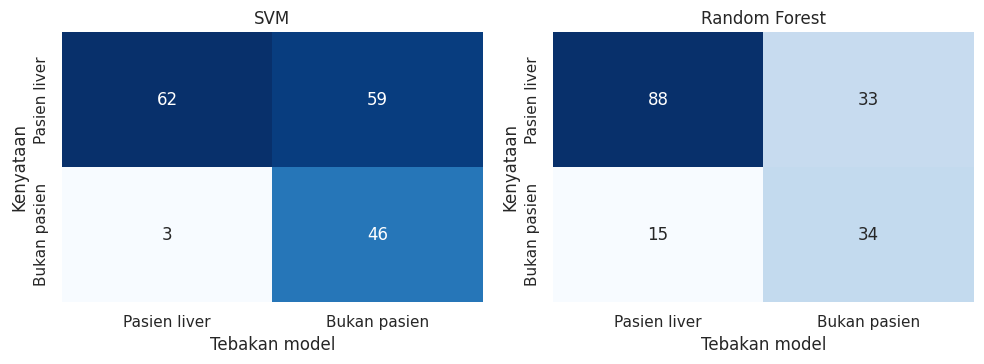

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, nama in zip(axes, ["SVM", "Random Forest"]):
    cm = metrik[nama]["confusion_matrix"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pasien liver", "Bukan pasien"], yticklabels=["Pasien liver", "Bukan pasien"])
    ax.set_title(nama); ax.set_xlabel("Tebakan model"); ax.set_ylabel("Kenyataan")
plt.tight_layout(); plt.show()

## 12. Fitur Terpenting (Random Forest)

**Apa ini?** Menunjukkan seberapa sering tiap fitur dipakai Random Forest untuk memisahkan kedua kelas. Makin panjang batang, makin sering dipakai.

**Catatan:** ini bukan bukti sebab-akibat, hanya gambaran fitur mana yang paling berguna bagi model.

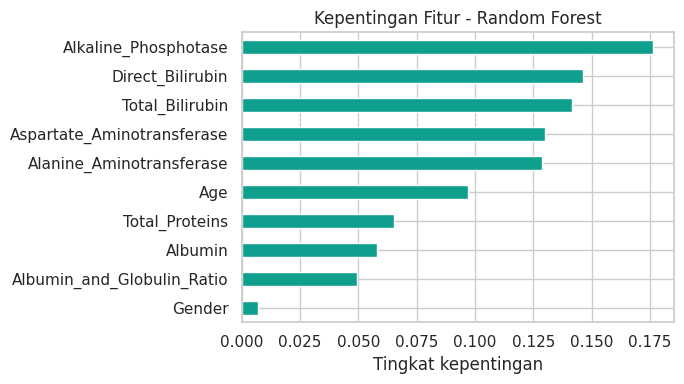

In [12]:
rf = model["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FITUR).sort_values(ascending=False)
metrik["Random Forest"]["importance"] = imp.to_dict()      # disimpan untuk aplikasi web

plt.figure(figsize=(7, 4))
imp.sort_values().plot(kind="barh", color="#0E9F8E")
plt.title("Kepentingan Fitur - Random Forest"); plt.xlabel("Tingkat kepentingan")
plt.tight_layout(); plt.show()

## 13. Uji Selisih Kedua Model (Bootstrap)

**Masalah:** data uji hanya sekitar 170 pasien. Selisih nilai yang kecil bisa terjadi hanya karena **keberuntungan** data yang kebetulan terpilih.

**Solusi (bootstrap):** data uji diambil ulang secara acak **2000 kali** (satu pasien boleh terambil dua kali). Di setiap pengambilan dihitung selisih nilai kedua model, lalu dilihat sebarannya.

**Cara membaca hasil (selang 95%):**
- Selang **tidak melewati angka 0** → selisih **nyata**
- Selang **melewati angka 0** → selisih bisa saja kebetulan

In [13]:
def bootstrap(y_test, pred_svm, pred_rf, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    y = np.asarray(y_test); ps = np.asarray(pred_svm); pr = np.asarray(pred_rf)

    def recall(yy, pp, kelas):
        m = yy == kelas
        return (pp[m] == kelas).mean()

    bs, br = [], []
    d_bacc, d_rl, d_rb = [], [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))                 # pilih pasien acak (boleh berulang)
        yy, a, c = y[i], ps[i], pr[i]
        bs.append(balanced_accuracy_score(yy, a)); br.append(balanced_accuracy_score(yy, c))
        d_bacc.append(br[-1] - bs[-1])
        d_rl.append(recall(yy, c, 1) - recall(yy, a, 1))
        d_rb.append(recall(yy, c, 2) - recall(yy, a, 2))

    pct = lambda v: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]   # selang 95%
    selisih = {}
    for nama, d, f in [("akurasi_seimbang", d_bacc, lambda p: balanced_accuracy_score(y, p)),
                       ("recall_liver", d_rl, lambda p: recall(y, p, 1)),
                       ("recall_bukan", d_rb, lambda p: recall(y, p, 2))]:
        ci = pct(d)
        selisih[nama] = {"nilai": float(f(pr) - f(ps)), "ci": ci, "signifikan": not (ci[0] <= 0 <= ci[1])}
    return pct(bs), pct(br), selisih


ci_svm, ci_rf, selisih = bootstrap(y_test, model["SVM"].predict(X_test), model["Random Forest"].predict(X_test))
metrik["SVM"]["ci_bacc"], metrik["Random Forest"]["ci_bacc"] = ci_svm, ci_rf

label = {"akurasi_seimbang": "Akurasi seimbang", "recall_liver": "Recall pasien liver", "recall_bukan": "Recall bukan pasien"}
print("Selisih (Random Forest - SVM), dalam poin persen:\n")
for k, d in selisih.items():
    print(f"{label[k]:<22} {d['nilai']*100:+6.1f}   selang 95% [{d['ci'][0]*100:+.1f} ; {d['ci'][1]*100:+.1f}]   ->",
          "NYATA" if d["signifikan"] else "tidak nyata (bisa kebetulan)")

Selisih (Random Forest - SVM), dalam poin persen:

Akurasi seimbang         -1.5   selang 95% [-8.9 ; +5.7]   -> tidak nyata (bisa kebetulan)
Recall pasien liver     +21.5   selang 95% [+14.8 ; +28.6]   -> NYATA
Recall bukan pasien     -24.5   selang 95% [-37.0 ; -12.2]   -> NYATA


## 14. Kumpulkan dan Simpan Hasil

**Apa ini?** Menyimpan hasil supaya aplikasi web tidak perlu belajar ulang.

- **`pickle`** menyimpan model yang sudah belajar (seperti menyimpan otak yang sudah terlatih).
- **`json`** menyimpan semua angka evaluasi untuk halaman "Perbandingan Model".

**Penting:** nama file harus persis seperti ini, dan file harus berada di folder proyek (satu folder dengan `webSVM.py`). Karena itu disimpan ke `FOLDER`, bukan ke folder notebook.

In [14]:
terbaik = max(metrik, key=lambda k: metrik[k]["akurasi_seimbang"])

hasil = {
    "best": terbaik,
    "selisih_rf_minus_svm": selisih,
    "n_train": len(X_train), "n_test": len(X_test), "n_total": len(X),
    "median_fitur": X.median().to_dict(),          # dipakai sebagai nilai awal kolom input di web
    "min_fitur": X.min().to_dict(), "max_fitur": X.max().to_dict(),
    "models": metrik,
}

# Simpan di folder proyek (FOLDER = tempat CSV berada), agar webSVM.py menemukannya
F_SVM = os.path.join(FOLDER, "svm_liver_pickle")
F_RF = os.path.join(FOLDER, "rf_liver_pickle")
F_JSON = os.path.join(FOLDER, "metrik_perbandingan.json")

with open(F_SVM, "wb") as f:
    pickle.dump(model["SVM"], f)
with open(F_RF, "wb") as f:
    pickle.dump(model["Random Forest"], f)
with open(F_JSON, "w") as f:
    json.dump(hasil, f, indent=2)

print("File tersimpan di folder proyek (satu folder dengan CSV):")
for path in [F_SVM, F_RF, F_JSON]:
    print(f" - {os.path.basename(path)}  ({os.path.getsize(path) / 1024:,.0f} KB)")

File tersimpan di folder proyek (satu folder dengan CSV):
 - svm_liver_pickle  (30 KB)
 - rf_liver_pickle  (1,974 KB)
 - metrik_perbandingan.json  (5 KB)


## 15. Coba Prediksi Satu Pasien (Contoh)

**Apa ini?** Membuktikan model yang tersimpan bisa dipakai. Model dimuat kembali dari file, lalu diberi **satu pasien contoh** (nilai median data), dan keduanya menebak.

Hasil `1` = pasien liver, `2` = bukan pasien liver. Ubah angka pada `contoh` untuk mencoba pasien lain.

In [15]:
with open(F_SVM, "rb") as f:
    svm_muat = pickle.load(f)
with open(F_RF, "rb") as f:
    rf_muat = pickle.load(f)

contoh = X.median().to_frame().T                           # 1 baris berisi nilai median tiap fitur
display(contoh)

arti = {1: "Pasien liver", 2: "Bukan pasien liver"}
print("Prediksi SVM          :", arti[int(svm_muat.predict(contoh)[0])])
print("Prediksi Random Forest:", arti[int(rf_muat.predict(contoh)[0])])
print(f"Skor liver (Random Forest): {rf_muat.predict_proba(contoh)[0][list(rf_muat.classes_).index(1)]:.1%}")

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alanine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio
0,45.000,1.000,1.000,0.300,208.000,35.000,41.000,6.600,3.100,0.950


Prediksi SVM          : Bukan pasien liver
Prediksi Random Forest: Bukan pasien liver
Skor liver (Random Forest): 49.9%


## 16. Kesimpulan

Sel di bawah menuliskan kesimpulan **otomatis dari angka hasil di atas**, sehingga selalu sesuai dengan hasil terbaru.

**Hal yang perlu diingat:**
- Jika selisih akurasi seimbang **tidak nyata**, kedua algoritma **setara** secara keseluruhan.
- Perbedaan biasanya ada pada **jenis kesalahan** (siapa yang lebih banyak terlewat), bukan pada siapa yang lebih pintar.
- Untuk skrining, **recall pasien liver** penting karena melewatkan pasien lebih merugikan.
- Hasil ini hanya untuk pembelajaran, **bukan diagnosis medis**.

In [16]:
S, R = metrik["SVM"], metrik["Random Forest"]
sb = selisih["akurasi_seimbang"]

print("KESIMPULAN OTOMATIS")
print("=" * 60)
print(f"1. Akurasi seimbang : SVM {S['akurasi_seimbang']:.1%} | Random Forest {R['akurasi_seimbang']:.1%}")
if sb["signifikan"]:
    print(f"   -> {terbaik} unggul secara keseluruhan (selisih nyata).")
else:
    print("   -> Selisih TIDAK nyata: kedua algoritma setara secara keseluruhan.")
print(f"2. Recall pasien liver : SVM {S['recall_liver']:.1%} | Random Forest {R['recall_liver']:.1%}")
print(f"3. Recall bukan pasien : SVM {S['recall_bukan']:.1%} | Random Forest {R['recall_bukan']:.1%}")
print(f"4. ROC-AUC             : SVM {S['auc']:.3f} | Random Forest {R['auc']:.3f}")
lebih_liver = "Random Forest" if R["recall_liver"] > S["recall_liver"] else "SVM"
print(f"5. Untuk skrining awal (jangan sampai pasien liver terlewat), {lebih_liver} lebih sesuai.")
print("=" * 60)

KESIMPULAN OTOMATIS
1. Akurasi seimbang : SVM 72.6% | Random Forest 71.1%
   -> Selisih TIDAK nyata: kedua algoritma setara secara keseluruhan.
2. Recall pasien liver : SVM 51.2% | Random Forest 72.7%
3. Recall bukan pasien : SVM 93.9% | Random Forest 69.4%
4. ROC-AUC             : SVM 0.786 | Random Forest 0.782
5. Untuk skrining awal (jangan sampai pasien liver terlewat), Random Forest lebih sesuai.


## Kamus Istilah Singkat

| Istilah | Artinya |
|---|---|
| **Fitur (X)** | data yang dipakai untuk menebak |
| **Target (y)** | jawaban yang benar |
| **Data latih / uji** | data untuk belajar / data untuk ujian |
| **Hyperparameter** | pengaturan model yang dipilih manusia (misal `C`, `gamma`, `max_depth`) |
| **GridSearchCV** | mencoba semua kombinasi pengaturan lalu memilih yang terbaik |
| **Validasi silang (CV)** | membagi data latih jadi beberapa bagian dan menguji bergantian |
| **Pipeline** | rangkaian langkah (misal: samakan skala, lalu model) menjadi satu paket |
| **Pickle** | file penyimpan model yang sudah dilatih |
| **Bootstrap** | mengambil ulang data secara acak berkali-kali untuk menguji kestabilan |